Prompt: I have a dataset called card_transdata.csv. Write some python code for loading in the dataset and printing the first few rows using pandas first by assigning it to a file_path variable,  then by reading it in. Also include seaborn, matplotlib and plotly.express for visualization and machine learning modeling imports.

AI: Claude Sonnet 5.5

In [1]:
# Data handling
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)


In [2]:
# Load the dataset
file_path = "card_transdata.csv"
transaction_data_raw = pd.read_csv(file_path)

# Preview the first few rows
print(transaction_data_raw.head())

   distance_from_home  distance_from_last_transaction  \
0           57.877857                        0.311140   
1           10.829943                        0.175592   
2            5.091079                             NaN   
3            2.247564                        5.600044   
4           44.190936                        0.566486   

   ratio_to_median_purchase_price  repeat_retailer  used_chip  \
0                        1.945940              1.0        1.0   
1                        1.294219              1.0        NaN   
2                        0.427715              1.0        0.0   
3                        0.362663              1.0        1.0   
4                        2.222767              1.0        1.0   

   used_pin_number  online_order  fraud  
0              0.0           0.0      0  
1              0.0           0.0      0  
2              0.0           1.0      0  
3              0.0           1.0      0  
4              0.0           1.0      0  


Prompt: Now display the shape, info and summary statistics for the dataset.

In [6]:
# Dataset shape (rows, columns)
transaction_data_raw.shape

(999, 8)

In [7]:
# Column data types and non-null counts
transaction_data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [8]:
# Summary statistics
transaction_data_raw.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


Prompt: Now, perform data wranging on the dataset. Check how many missing values there are and drop rows with missing values, then print the first few rows of the cleaned dataset.

AI: Claude Sonnet 5.5

In [10]:
# Data wrangling: check for missing values
transaction_data_raw.isnull().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

In [12]:
# Drop rows with missing values, then make a copy
transaction_data_cleaned = transaction_data_raw.dropna().copy()
print(transaction_data_cleaned.shape)

(977, 8)


In [13]:
# Preview the cleaned dataset
print(transaction_data_cleaned.head())

   distance_from_home  distance_from_last_transaction  \
0           57.877857                        0.311140   
3            2.247564                        5.600044   
4           44.190936                        0.566486   
5            5.586408                       13.261073   
6            3.724019                        0.956838   

   ratio_to_median_purchase_price  repeat_retailer  used_chip  \
0                        1.945940              1.0        1.0   
3                        0.362663              1.0        1.0   
4                        2.222767              1.0        1.0   
5                        0.064768              1.0        0.0   
6                        0.278465              1.0        0.0   

   used_pin_number  online_order  fraud  
0              0.0           0.0      0  
3              0.0           1.0      0  
4              0.0           1.0      0  
5              0.0           0.0      0  
6              0.0           1.0      0  


Prompt: Now, write code to visualize the distribution. First, make a countplot titled Fraud Class Distribution of the fraud variable, a countplot titled Used Pin Distribution of the used_pin_number variable, a countplot titled Repeat Retailer Distribution of the repeat_retailer variable, a countplot titled Online orders of the online_order variable, a histplot titled Ratio to Median Purchase Price Distribution of ratio_to_mean_purchase_price with 30 bins and a histplot titled Distance From Home Distribution of the distance_from_home variable. Show all plots in separate boxes.

AI: Claude Sonnet 5.5

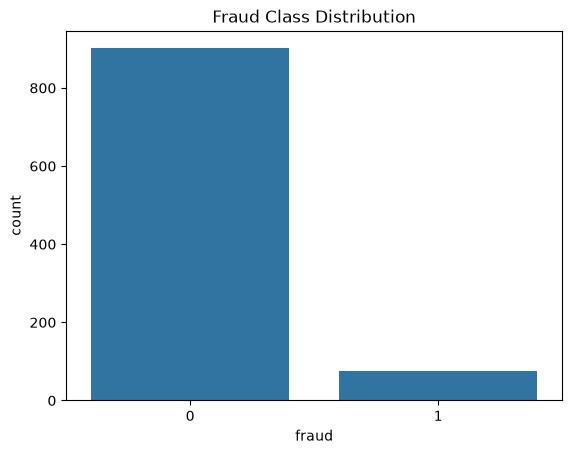

In [14]:
# Fraud class distribution
sns.countplot(data=transaction_data_cleaned, x="fraud")
plt.title("Fraud Class Distribution")
plt.show()

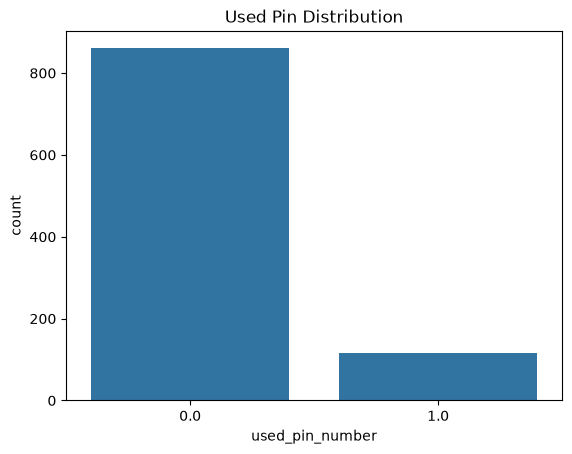

In [15]:
# Used PIN distribution
sns.countplot(data=transaction_data_cleaned, x="used_pin_number")
plt.title("Used Pin Distribution")
plt.show()

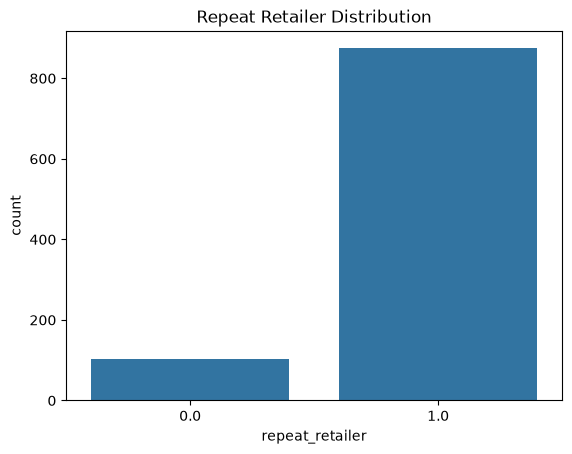

In [16]:
# Repeat retailer distribution
sns.countplot(data=transaction_data_cleaned, x="repeat_retailer")
plt.title("Repeat Retailer Distribution")
plt.show()

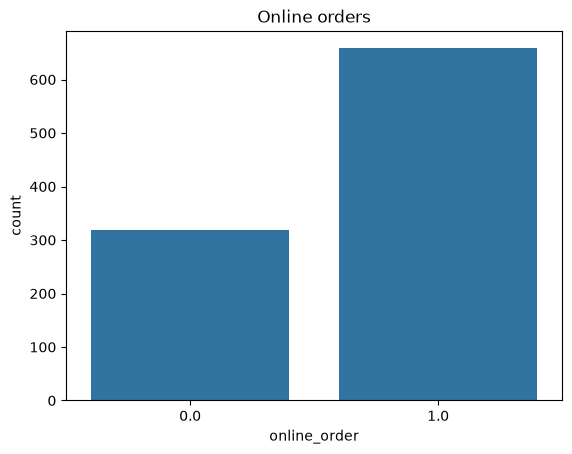

In [17]:
# Online orders
sns.countplot(data=transaction_data_cleaned, x="online_order")
plt.title("Online orders")
plt.show()

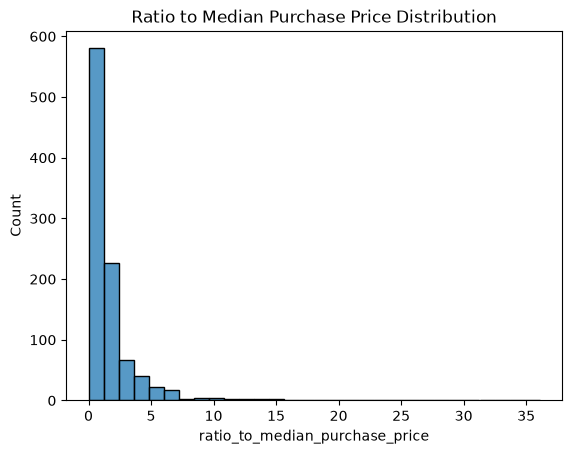

In [20]:
# Ratio to median purchase price distribution
sns.histplot(transaction_data_cleaned["ratio_to_median_purchase_price"], bins=30)
plt.title("Ratio to Median Purchase Price Distribution")
plt.show()

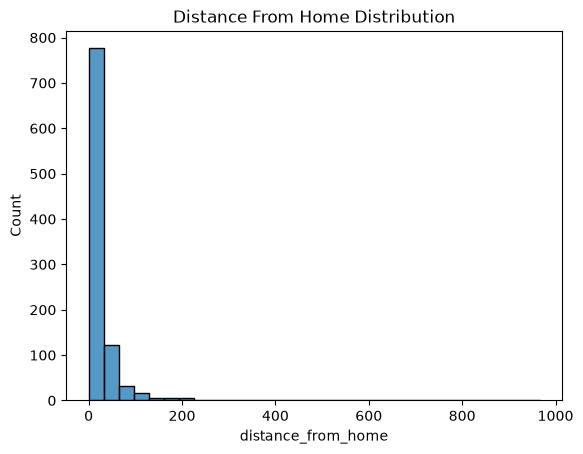

In [22]:
# Distance from home distribution
sns.histplot(transaction_data_cleaned["distance_from_home"], bins=30)
plt.title("Distance From Home Distribution")
plt.show()

Now, create bivariate visualizations. First, create a countplot of used_pin_number with a hue of fraud and a palette that is green and red. Title it Transactions with PIN vs Fraudulent Transactions with Used PIN on the x-axis and Count on the y-axis. Have a legend titled Fraud with Fraudulent and Non-Fraudulent Labels. Then create a percentage plot for the percentage of fraudulent transactions depending on if a pin is used or not. Title this bar plot Percentage of Fraudulent Transactions with PIN Usage with x and y labels as well as a legend.

AI: Claude Sonnet 5.5

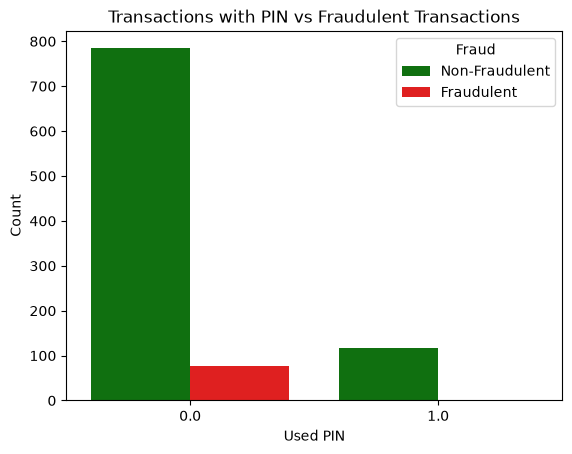

In [23]:
# Used PIN vs fraud (counts)
sns.countplot(data=transaction_data_cleaned, x="used_pin_number", hue="fraud", palette=["green", "red"])
plt.title("Transactions with PIN vs Fraudulent Transactions")
plt.xlabel("Used PIN")
plt.ylabel("Count")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.show()

In [25]:
# Percentage of fraudulent transactions by PIN usage
df_pin_fraud = (
    transaction_data_cleaned.groupby("used_pin_number")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    * 100
)

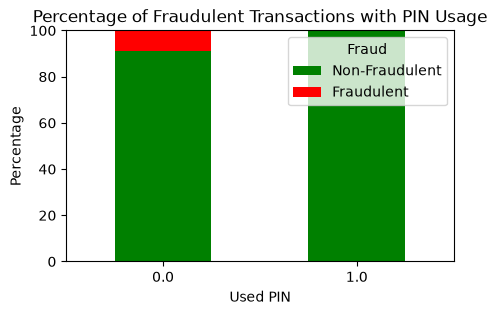

In [27]:
df_pin_fraud.plot(kind="bar", stacked=True, figsize=(5, 3), color=["green", "red"])
plt.title("Percentage of Fraudulent Transactions with PIN Usage")
plt.xlabel("Used PIN")
plt.ylabel("Percentage")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.xticks(rotation=0)
plt.show()

Prompt: Now, create a countplot to show the  number of transactions that were fraud or not when a chip  is used or not. Have x be used_chip and called Used Chip, y be labelled count, with fraud as the hue. Keep the same fig size and legend as before. Next, mimic the most recent percentage plot created, now to see the percentage of fraudulent transactions when a chip is used or not.

AI: Claude Sonnet 5.5

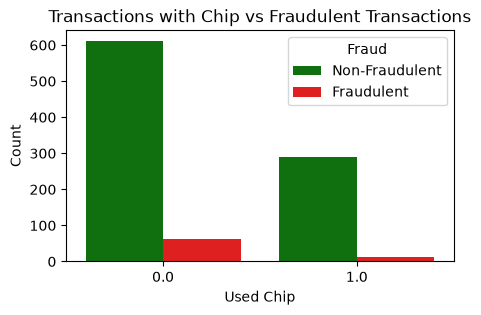

In [28]:
# Used chip vs fraud (counts)
plt.figure(figsize=(5, 3))
sns.countplot(data=transaction_data_cleaned, x="used_chip", hue="fraud", palette=["green", "red"])
plt.title("Transactions with Chip vs Fraudulent Transactions")
plt.xlabel("Used Chip")
plt.ylabel("Count")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.show()

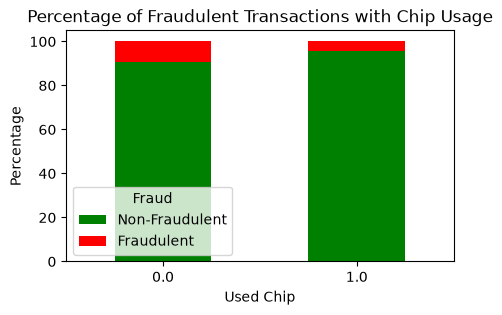

In [29]:
# Percentage of fraudulent transactions by chip usage
df_chip_fraud = (
    transaction_data_cleaned.groupby("used_chip")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    * 100
)

df_chip_fraud.plot(kind="bar", stacked=True, figsize=(5, 3), color=["green", "red"])
plt.title("Percentage of Fraudulent Transactions with Chip Usage")
plt.xlabel("Used Chip")
plt.ylabel("Percentage")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.xticks(rotation=0)
plt.show()

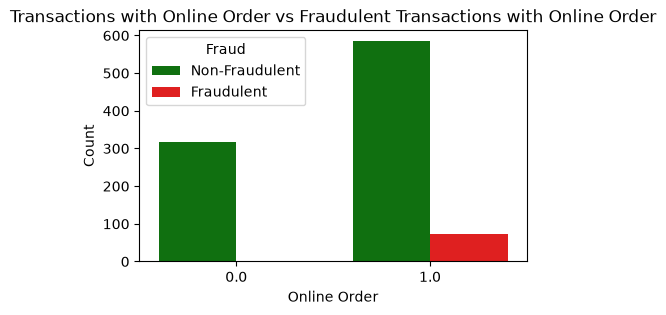

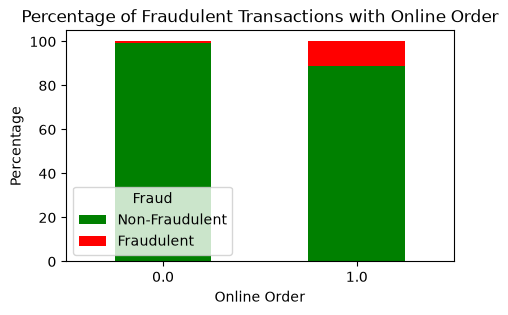

In [31]:
# Online order vs fraud (counts)
plt.figure(figsize=(5, 3))
sns.countplot(data=transaction_data_cleaned, x="online_order", hue="fraud", palette=["green", "red"])
plt.title("Transactions with Online Order vs Fraudulent Transactions with Online Order")
plt.xlabel("Online Order")
plt.ylabel("Count")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.show()

# Percentage of fraudulent transactions by online order
df_online_order_fraud = (
    transaction_data_cleaned.groupby("online_order")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    * 100
)

df_online_order_fraud.plot(kind="bar", stacked=True, figsize=(5, 3), color=["green", "red"])
plt.title("Percentage of Fraudulent Transactions with Online Order")
plt.xlabel("Online Order")
plt.ylabel("Percentage")
plt.legend(title="Fraud", labels=["Non-Fraudulent", "Fraudulent"])
plt.xticks(rotation=0)
plt.show()

Prompt: Create a scatterplot titled Fraudulent vs. Non-Fraudulent Transactions: Distance from Last Transaction vs Ratio to Median Purchase Price with Distance from Last Transaction for distance_from_last_transaction and Ratio to Median Purchase Price for ratio_to_median_purchase_price with a green and red palette. Figure size should be 10 by 6. Have the same format scatterplot for distance_from_home and ratio_to_median_purchase_price(on y-axis).

AI: Claude Sonnet 5.5

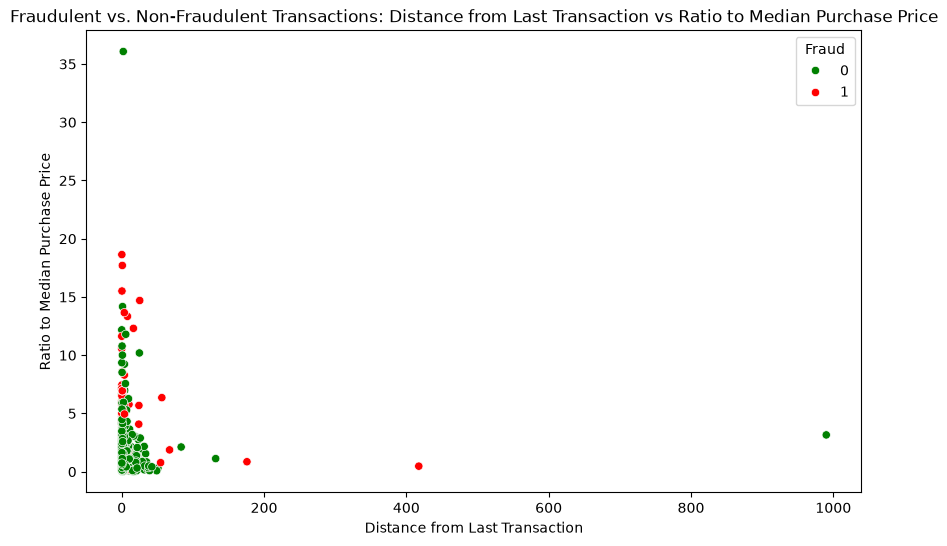

In [34]:
# Scatterplot: distance from last transaction vs ratio to median purchase price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=transaction_data_cleaned,
    x="distance_from_last_transaction",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    palette={0: "green", 1: "red"},
)
plt.title("Fraudulent vs. Non-Fraudulent Transactions: Distance from Last Transaction vs Ratio to Median Purchase Price")
plt.xlabel("Distance from Last Transaction")
plt.ylabel("Ratio to Median Purchase Price")
plt.legend(title="Fraud")
plt.show()

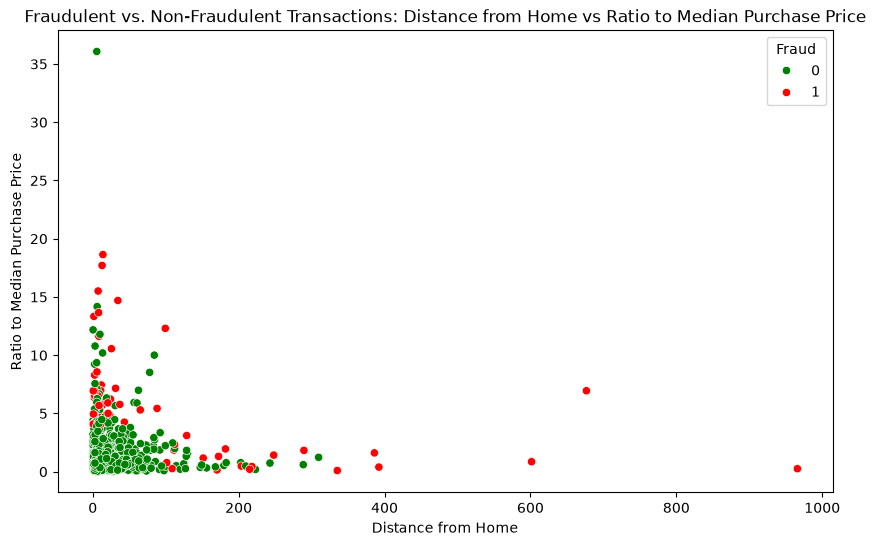

In [35]:
# Scatterplot: distance from home vs ratio to median purchase price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=transaction_data_cleaned,
    x="distance_from_home",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    palette={0: "green", 1: "red"},
)
plt.title("Fraudulent vs. Non-Fraudulent Transactions: Distance from Home vs Ratio to Median Purchase Price")
plt.xlabel("Distance from Home")
plt.ylabel("Ratio to Median Purchase Price")
plt.legend(title="Fraud")
plt.show()

Prompt: Now, let us do machine learning. Select features and with the target variable of fraud, assigning them to X and Y. Split the data into training and test sets with 80% being called X_train and y_train and the other 20% being X_test and y_test. Have the random state be 42 and stratify on y. Also put X_train, y_train, X_test, and y_test on their own lines to display them.

AI: Claude Sonnet 5.5

In [36]:
# Select features and target
X = transaction_data_cleaned.drop("fraud", axis=1)
y = transaction_data_cleaned["fraud"]

# Split into 80% training and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [37]:
X_train

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
954,39.904167,0.367448,0.260833,1.0,1.0,0.0,1.0
143,2.660649,0.657162,3.837860,1.0,0.0,0.0,1.0
643,48.902727,0.205816,1.307000,1.0,0.0,1.0,0.0
15,179.665148,0.120920,0.535640,1.0,1.0,1.0,1.0
793,676.702348,1.209733,6.948586,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...
685,5.916343,5.099247,0.419779,1.0,0.0,0.0,0.0
722,23.517527,3.513485,0.241444,1.0,0.0,0.0,0.0
173,3.273426,1.056948,1.694281,1.0,0.0,0.0,1.0
499,7.387696,1.598827,0.847218,1.0,0.0,0.0,1.0


In [39]:
y_train

954    0
143    0
643    0
15     0
793    1
      ..
685    0
722    0
173    0
499    0
593    0
Name: fraud, Length: 781, dtype: int64

In [41]:
X_test

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
782,0.701100,0.540487,1.754568,0.0,0.0,0.0,1.0
51,43.281314,3.367793,0.676058,1.0,1.0,1.0,1.0
197,4.586564,3.365070,2.454288,1.0,0.0,0.0,0.0
550,4.403263,0.173726,0.641169,1.0,0.0,0.0,0.0
412,965.910612,0.023604,0.257908,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...
436,6.498016,0.228995,0.171750,1.0,0.0,0.0,0.0
868,9.258344,0.633609,0.066744,1.0,1.0,0.0,1.0
65,17.797888,1.395508,2.880479,1.0,1.0,0.0,0.0
743,5.599947,2.477098,5.956153,1.0,0.0,0.0,0.0


In [42]:
y_test

782    0
51     0
197    0
550    0
412    1
      ..
436    0
868    0
65     0
743    0
390    0
Name: fraud, Length: 196, dtype: int64

Prompt: Create a model that is never fraud, calling it y_pred_never_fraud and print the first 100 predictions. Also create a confusion matrix for it called conf_matrix_never_fraud, setting a variable acc as the accuracy. Create a heatmap of this matrix with a x-label of Predicted, y-label of Actual, and title of Never Fraud Model Performance: __% accuracy, where the blank is filled in.

AI: Claude Sonnet 5.5

In [43]:
# Never-fraud baseline: predict 0 (non-fraud) for every test transaction
y_pred_never_fraud = [0] * len(y_test)

# Print the first 100 predictions
print(y_pred_never_fraud[:100])


[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


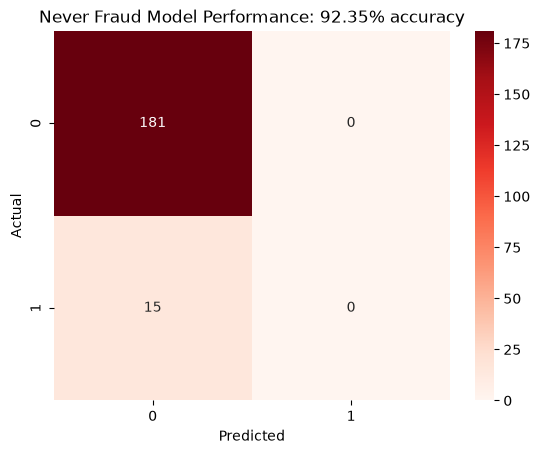

In [45]:
# Confusion matrix and accuracy
conf_matrix_never_fraud = confusion_matrix(y_test, y_pred_never_fraud)
acc = accuracy_score(y_test, y_pred_never_fraud)

# Heatmap of the confusion matrix
sns.heatmap(conf_matrix_never_fraud, annot=True, fmt="d", cmap="Reds")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Never Fraud Model Performance: {acc * 100:.2f}% accuracy")
plt.show()

Prompt: Now, we will make a k nearest neighbor model. Assign a knn classifier to knn and fit it. Assign predictions to  y_pred_knn and print the first 100 predictions. Use the same formatting to create a similar confusion matrix and heatmap, rounding accuracy to one decimal point. Call the confusion matrix conf_matrix_knn with a title of 3-NN Performance: __ % accuracy.

AI: Claude Sonnet 5.5

In [47]:
# Create and fit a 3-nearest-neighbors classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Predict on the test set and print the first 100 predictions
y_pred_knn = knn.predict(X_test)
print(y_pred_knn[:100])

[0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]


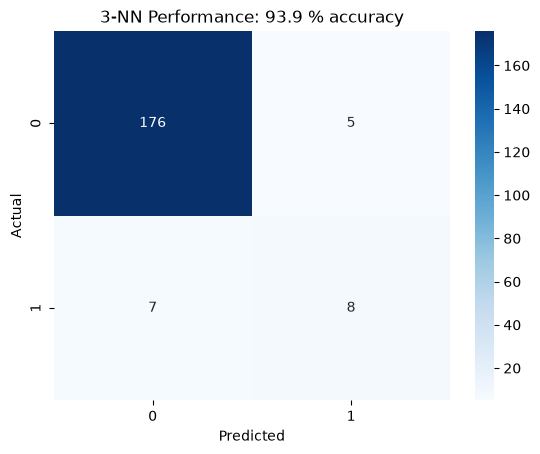

In [49]:
# Confusion matrix and accuracy
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
acc = accuracy_score(y_test, y_pred_knn)

# Heatmap of the confusion matrix
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"3-NN Performance: {acc * 100:.1f} % accuracy")
plt.show()

Prompt: Compute metrics for never fraud called accuracy_never_fraud, precision_never_fraud, recall_never_fraud and f1_never_fraud. Use the same type of naming for knn metrics. Next, prepare data for visualization by setting Accuracy, Precision, Recall and F1 Score to metrics, creating knn_scores and never_fraud_scores lists and comparison_transaction_data, a dataframe of Metric, k-NN and Never Fraud. For plotting, use a fig and ax with size (10,6) and set variables of bar_width of 0.35 and index for the range of the length of metrics. Assign to bar1 knn_scores with a label of k-NN and color it blue. Assign to bar2 never_fraud_scores with a label of Never Fraud and color it red. Use the bar_width for both. Label x Metric and y  Score with a title of Model Performance Comparison. Set x ticks, with x ticks being index plus bar width divided by 2 for each index. Set the y limit to 1 and have a legend of k-NN and Never Fraud.

AI: Claude Sonnet 5.5

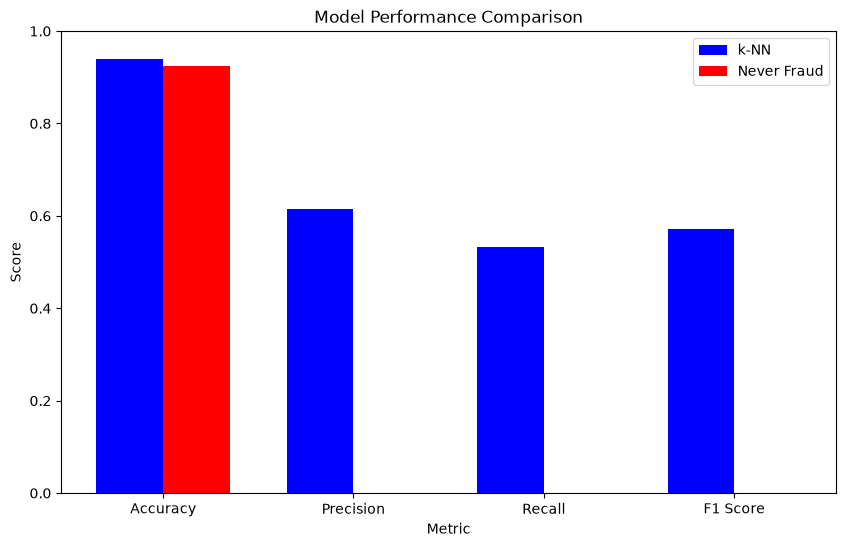

In [50]:
# Metrics for the never-fraud model
accuracy_never_fraud = accuracy_score(y_test, y_pred_never_fraud)
precision_never_fraud = precision_score(y_test, y_pred_never_fraud, zero_division=0)
recall_never_fraud = recall_score(y_test, y_pred_never_fraud)
f1_never_fraud = f1_score(y_test, y_pred_never_fraud, zero_division=0)

# Metrics for the k-NN model
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

# Prepare data for visualization
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

knn_scores = [accuracy_knn, precision_knn, recall_knn, f1_knn]
never_fraud_scores = [
    accuracy_never_fraud,
    precision_never_fraud,
    recall_never_fraud,
    f1_never_fraud,
]

comparison_transaction_data = pd.DataFrame({
    "Metric": metrics,
    "k-NN": knn_scores,
    "Never Fraud": never_fraud_scores,
})

# Grouped bar chart comparing k-NN and Never Fraud
fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.35
index = range(len(metrics))

bar1 = ax.bar(index, knn_scores, bar_width, label="k-NN", color="blue")
bar2 = ax.bar(
    [i + bar_width for i in index],
    never_fraud_scores,
    bar_width,
    label="Never Fraud",
    color="red",
)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison")
ax.set_xticks([i + bar_width / 2 for i in index])
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend(["k-NN", "Never Fraud"])